In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.1


In [3]:
train = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_test.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

In [4]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)


In [5]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 661us/step - accuracy: 0.8316 - loss: 0.6827 - val_accuracy: 0.9137 - val_loss: 0.3234
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 596us/step - accuracy: 0.9020 - loss: 0.3529 - val_accuracy: 0.9282 - val_loss: 0.2609
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 594us/step - accuracy: 0.9153 - loss: 0.3021 - val_accuracy: 0.9365 - val_loss: 0.2310
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 747us/step - accuracy: 0.9238 - loss: 0.2712 - val_accuracy: 0.9398 - val_loss: 0.2130
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 682us/step - accuracy: 0.9303 - loss: 0.2482 - val_accuracy: 0.9477 - val_loss: 0.1948
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 632us/step - accuracy: 0.9356 - loss: 0.2293 - val_accuracy: 0.9507 - val_loss: 0.1815
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 712us/step - accuracy: 0.9395 - loss: 0.2135 - val_accuracy: 0.9537 - val_loss: 0.1710
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 686us/step - accuracy: 0.9432 -

In [8]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.1599
Test Accuracy: 95.32 %


In [9]:
prediction = model.predict(x_test[:1], verbose=0)

predicted_digit = prediction.argmax(axis=1)[0]

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[0])

Predicted digit: 7
Actual digit: 7


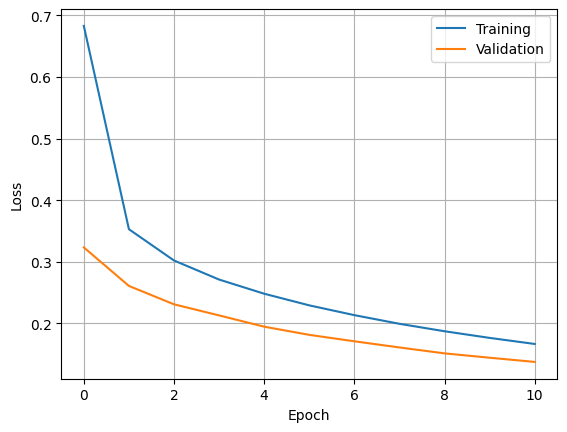

In [10]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

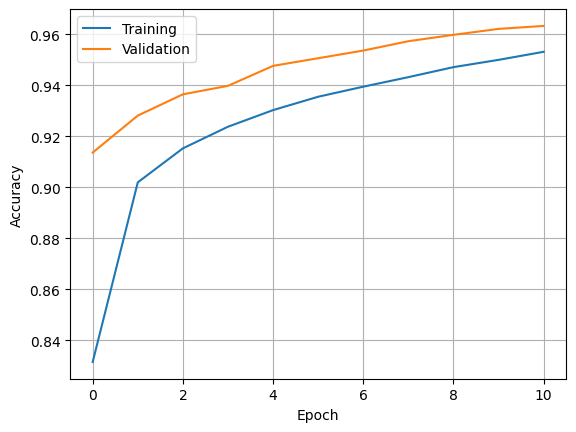

In [11]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()